# Latih & Validasi Model ANAK_BALITA

**Pemilik:** Arya · **Algoritma:** Logistic Regression multinomial (label 0 tidak sesuai / 1 cukup / 2 sangat sesuai)

Notebook ini menggantikan `latih_anak_balita.py` dan `validasi_anak_balita.py`. Kode training, fitur, hyperparameter, dan seed
sama untuk keempat kategori (`shared/training.py`); yang khusus kategori ada di `anak_balita/ai_models/`
(`profil.py`, `rubrik.py`, `bahaya.py`, `skenario.py`).

**Skema evaluasi**

| Tahap | Data | Tujuan |
|---|---|---|
| Validasi silang GroupKFold 5 lipatan | 80% profil (data latih) | skor latih vs validasi per lipatan, cek overfitting, kurva belajar |
| Test set (held-out) | 20% profil baru + 15% makanan baru | estimasi akhir yang jujur, dipakai **sekali** untuk model final |

Split dilakukan **per profil**: profil yang sama tidak pernah muncul di data latih dan validasi/test sekaligus.

**Cara menjalankan:** buka di VS Code / JupyterLab / Colab, lalu *Run All*. Hugging Face Space tetap menjalankan
`app.py` (API); notebook ini hanya untuk melatih model dan membuat laporan. Model hasil latih disimpan ke
`anak_balita/model/recommender_ANAK_BALITA.joblib` dan dipakai API.

In [1]:
import os, sys

# Cari root repo (folder yang berisi model.py) agar notebook bisa dijalankan dari folder mana pun
ROOT = os.path.abspath(os.getcwd())
while not os.path.exists(os.path.join(ROOT, 'model.py')):
    if os.path.dirname(ROOT) == ROOT:
        raise RuntimeError('Root repo (model.py) tidak ditemukan. Jalankan notebook dari dalam repo.')
    ROOT = os.path.dirname(ROOT)
sys.path.insert(0, ROOT)
os.chdir(ROOT)
os.environ.setdefault('AI_ALLOW_SNAPSHOT_FALLBACK', '1')   # uji end-to-end memakai snapshot bila Supabase offline

KATEGORI = 'ANAK_BALITA'
BUAT_DATA = False      # True = buat ulang dataset sintetis dari profil.py & rubrik.py kategori ini
JUMLAH_PROFIL = 700

import pandas as pd
from IPython.display import Markdown, display
from shared import PEMILIK, data_dir
from shared import grafik
from shared.pipeline import latih_kategori, validasi_kategori

pd.set_option('display.width', 160)
print(f'Model {KATEGORI} | pemilik {PEMILIK[KATEGORI]} | root {ROOT}')

Model ANAK_BALITA | pemilik Arya | root D:\Semester 6\Proyek Perangkat Lunak I\AINutriScale\ai_recommendation_railway


## 1. Dataset sintetis

,baris,profil,makanan unik,baris makanan baru
Latih,33589,560,6844,0
Test,8399,140,4807,1331


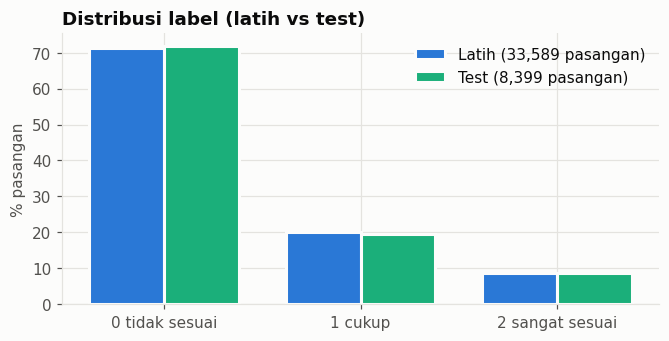

In [2]:
if BUAT_DATA:
    from shared.dataset import generate_category_dataset, load_food_catalog
    generate_category_dataset(load_food_catalog(os.path.join(ROOT, 'data', 'nutrition.csv')), KATEGORI, JUMLAH_PROFIL)

df_train = pd.read_csv(os.path.join(data_dir(KATEGORI), 'train_data.csv'))
df_test = pd.read_csv(os.path.join(data_dir(KATEGORI), 'test_data.csv'))
display(pd.DataFrame({
    'baris': [len(df_train), len(df_test)],
    'profil': [df_train['profile_id'].nunique(), df_test['profile_id'].nunique()],
    'makanan unik': [df_train['food_name'].nunique(), df_test['food_name'].nunique()],
    'baris makanan baru': [int(df_train['is_new_food'].sum()), int(df_test['is_new_food'].sum())],
}, index=['Latih', 'Test']))
grafik.distribusi_label(df_train, df_test)

## 2. Latih model

Validasi silang, model final, pembanding gradient boosting, dan kurva belajar (sekitar 1-2 menit).

In [3]:
h = latih_kategori(KATEGORI)

  NUTRISCALE AI — MODEL ANAK_BALITA (pemilik: Arya)
  Logistic Regression multinomial | skor = (P(cukup) + 2 * P(sangat sesuai)) / 2



[ANAK_BALITA] Memuat Dataset:
  - Training samples : 33589 baris (560 profil)
  - Testing samples  : 8399 baris (140 profil baru, Held-Out)
  - Distribusi label : {0: 0.712, 1: 0.202, 2: 0.086}
  - Fitur input      : 99 fitur (model.FEATURE_COLS)


  GroupKFold (5 fold): kappa 0.9158 ± 0.0024 | macro-F1 latih 0.8919 vs validasi 0.8874 ± 0.0015 | NDCG@5 0.9857


  Test (profil baru): Acc 0.9374 | macro-F1 0.8950 | kappa 0.9234
  Macro precision 0.8933 | macro recall 0.8968
    Kelas 0: precision 0.9729 | recall 0.9706 | F1 0.9718 | n=6030
    Kelas 1: precision 0.8380 | recall 0.8411 | F1 0.8395 | n=1636
    Kelas 2: precision 0.8691 | recall 0.8786 | F1 0.8738 | n=733
  Confusion matrix (baris=asli, kolom=prediksi): [[5853, 177, 0], [163, 1376, 97], [0, 89, 644]]
  NDCG@5  model 0.9873 | formula lama 0.6819 | acak 0.5041
  Subset makanan baru (1331 baris): macro-F1 0.8935 | kappa 0.9231
  Pasangan konflik yang tetap diberi label > 0 oleh model saja: 0.00% (di produksi dibuang dulu oleh safety filter)
  Pembanding gradient boosting: Acc 0.9615 | macro-F1 0.9325 | kappa 0.9530 | NDCG@5 0.9931
  Overfitting: macro-F1 latih 0.8906 | validasi CV 0.8874 | test 0.8950 -> tidak overfitting (gradient boosting: selisih +0.0547)
  Koefisien teratas (P2 vs P0): [('natrium_lewat_jauh', -8.4174), ('fat_share', -7.9305), ('gula_lewat_jauh', -7.835), ('porsi

## 3. Validasi silang GroupKFold (latih vs validasi)

Tiap lipatan melatih model di 4/5 profil latih dan menguji di 1/5 profil sisanya. Kolom `train_*` = skor pada data
yang dipakai melatih, `val_*` = skor pada profil yang belum pernah dilihat.

,train_accuracy,val_accuracy,train_macro_f1,val_macro_f1,selisih_f1,train_log_loss,val_log_loss,val_weighted_kappa,val_ndcg@5
fold,,,,,,,,,
1,0.9352,0.9311,0.8920,0.8876,0.0044,0.1512,0.1607,0.9151,0.9870
2,0.9350,0.9355,0.8921,0.8885,0.0036,0.1505,0.1620,0.9186,0.9880
3,0.9338,0.9308,0.8911,0.8849,0.0062,0.1521,0.1554,0.9139,0.9836
4,0.9347,0.9300,0.8915,0.8880,0.0035,0.1515,0.1584,0.9134,0.9823
5,0.9345,0.9329,0.8926,0.8882,0.0044,0.1527,0.1544,0.9182,0.9878


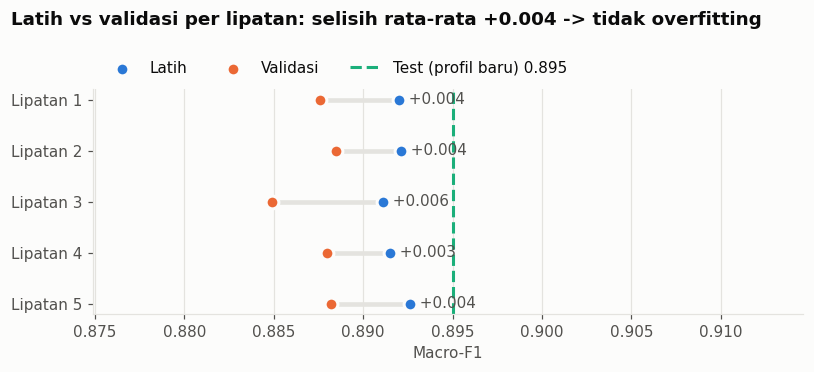

In [4]:
display(grafik.tabel_cv_per_fold(h))
grafik.latih_vs_validasi(h)

## 4. Cek overfitting

Overfitting = model menghafal data latih: skor latih jauh lebih tinggi daripada skor data baru.
Ukurannya adalah **selisih macro-F1 latih − validasi/test**:

| Selisih | Kesimpulan |
|---|---|
| ≤ 0,02 | tidak overfitting |
| ≤ 0,05 | overfitting ringan |
| > 0,05 | overfitting |

Bila skor latih **dan** validasi sama-sama rendah, masalahnya underfitting (model terlalu sederhana), bukan overfitting.
Gradient boosting ditampilkan sebagai pembanding model yang lebih kompleks.

accuracy  macro_f1  weighted_kappa  log_loss
Model               Data                                                                 
Logistic Regression Latih (model final)        0.9341    0.8906          0.9184    0.1520
                    Latih (rata-rata CV)       0.9346    0.8919          0.9191    0.1516
                    Validasi (rata-rata CV)    0.9321    0.8874          0.9158    0.1582
                    Test (profil baru)         0.9374    0.8950          0.9234    0.1489
Gradient boosting   Latih                      0.9927    0.9872          0.9910    0.0429
                    Test (profil baru)         0.9615    0.9325          0.9530    0.1012

Logistic Regression : selisih F1 latih-CV +0.0044, latih-test -0.0044 -> tidak overfitting
Gradient boosting   : selisih F1 latih-test +0.0547 -> overfitting


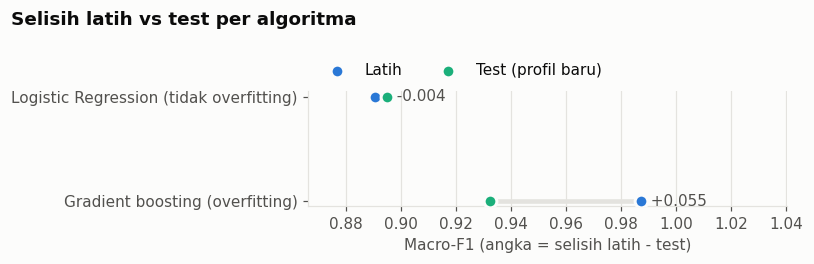

In [5]:
o = h['overfitting']
display(grafik.tabel_overfitting(h))
print(f"Logistic Regression : selisih F1 latih-CV {o['selisih_f1_train_vs_cv']:+.4f}, latih-test {o['selisih_f1_train_vs_test']:+.4f} -> {o['kesimpulan']}")
gb = o['pembanding_gradient_boosting']
print(f"Gradient boosting   : selisih F1 latih-test {gb['selisih_f1_train_vs_test']:+.4f} -> {gb['kesimpulan']}")
grafik.overfitting_lr_vs_gb(h)

### Kurva belajar

Model dilatih ulang dengan 10%..100% profil latih. Bila garis latih dan validasi bertemu di nilai tinggi, model
tidak overfitting; jarak lebar yang menetap = overfitting; keduanya rendah = underfitting.

,n_profil_latih,train_macro_f1,train_std,val_macro_f1,val_std
fraksi,,,,,
0.1,45,0.9085,0.0066,0.8677,0.0067
0.2,90,0.9014,0.0093,0.8802,0.0028
0.4,179,0.8963,0.0037,0.8876,0.0014
0.6,269,0.8936,0.0019,0.8881,0.0014
0.8,358,0.8936,0.0008,0.8878,0.0015
1.0,448,0.8919,0.0005,0.8874,0.0013


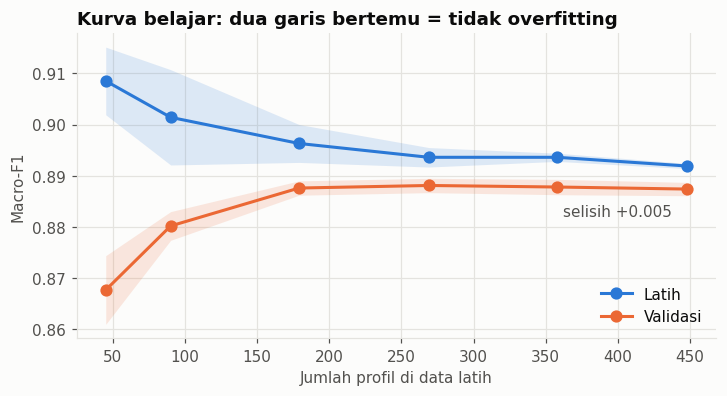

In [6]:
display(pd.DataFrame(h['kurva_belajar']).set_index('fraksi'))
grafik.kurva_belajar(h)

## 5. Test set (profil baru)

Accuracy 0.9374 | macro-F1 0.8950 | weighted kappa 0.9234 | log loss 0.1489
Subset makanan baru (tidak ada di data latih): macro-F1 0.8935 | kappa 0.9231


,precision,recall,f1,support
0 tidak sesuai,0.9729,0.9706,0.9718,6030.0
1 cukup,0.8380,0.8411,0.8395,1636.0
2 sangat sesuai,0.8691,0.8786,0.8738,733.0


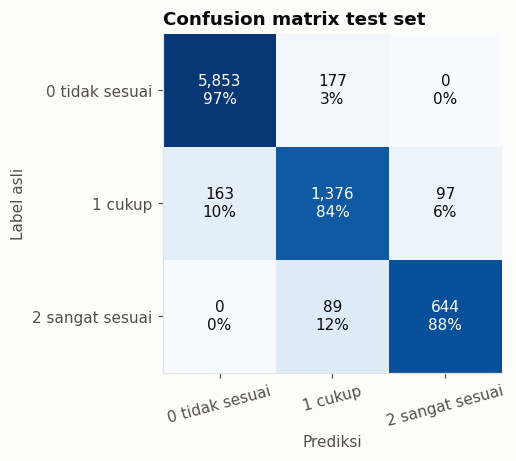

In [7]:
t = h['test']
print(f"Accuracy {t['accuracy']:.4f} | macro-F1 {t['macro_f1']:.4f} | weighted kappa {t['weighted_kappa']:.4f} | log loss {t['log_loss']:.4f}")
nf = h['test_new_food']
print(f"Subset makanan baru (tidak ada di data latih): macro-F1 {nf.get('macro_f1', 0):.4f} | kappa {nf.get('weighted_kappa', 0):.4f}")
display(grafik.tabel_per_kelas(h))
grafik.confusion(h)

## 6. Pembanding

,Accuracy,F1 (macro),Kappa,NDCG@5
Logistic Regression (model),0.9374,0.8950,0.9234,0.9873
Gradient boosting,0.9615,0.9325,0.9530,0.9931
Formula lama,NaN,NaN,NaN,0.6819
Urutan acak,NaN,NaN,NaN,0.5041


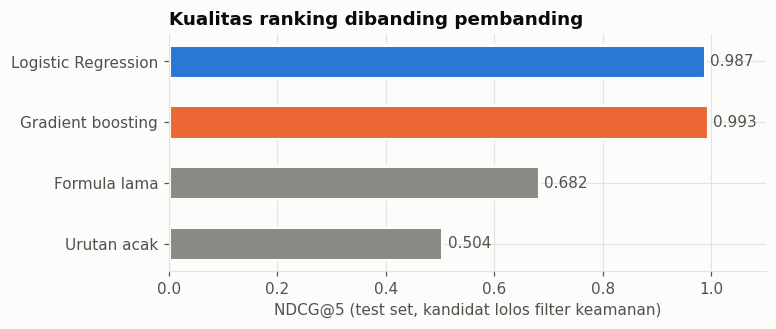

In [8]:
display(grafik.tabel_pembanding(h))
grafik.pembanding_ndcg(h)

## 7. Koefisien model

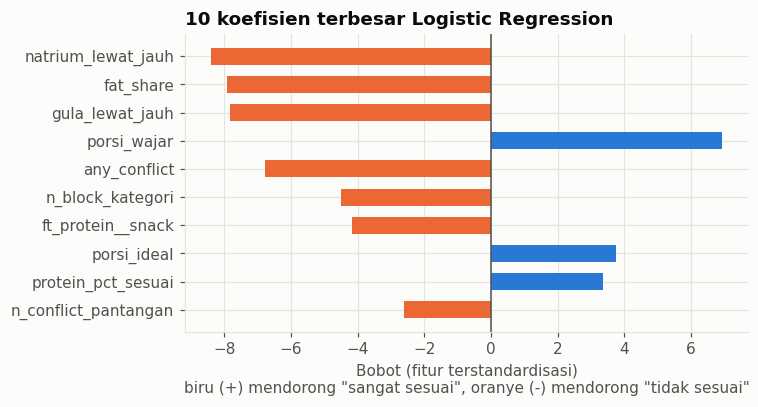

In [9]:
grafik.koefisien(h)

## 8. Uji end-to-end & laporan validasi

Skenario kategori dijalankan lewat pipeline produksi (filter keamanan + model + penyusun menu) memakai katalog
produk Supabase (atau snapshot lokal bila offline). Laporan disimpan ke `outputs/`.

In [10]:
path = validasi_kategori(KATEGORI)
with open(path, encoding='utf-8') as f:
    display(Markdown(f.read()))

[Pipeline] Memuat data makanan dari http://localhost:3000/api/products...
[Pipeline] Sukses memuat data makanan dari Next.js API (50 item).
[Pipeline] OK: 46 makanan siap dengan deteksi alergen & fitur ML.


[ANAK_BALITA] Acc 0.9374 | Prec 0.8933 | Recall 0.8968 | F1 0.8950 | Kappa 0.9234
[ANAK_BALITA] Pelanggaran alergen/BLOKIR/tekstur: 0/0/0
[ANAK_BALITA] Laporan: D:\Semester 6\Proyek Perangkat Lunak I\AINutriScale\ai_recommendation_railway\anak_balita\outputs\laporan_validasi_anak_balita.md


# Laporan Validasi Model ANAK_BALITA

- Pemilik: **Arya**
- Metode: Logistic Regression multinomial (label 0/1/2), metode dan konfigurasi sama dengan 3 kategori lain (config hash `7ec1c77b29e130d2`)
- Data: 560 profil latih (33589 pasangan), 140 profil uji baru (8399 pasangan); split per profil
- Evaluasi: validasi silang GroupKFold 5 lipatan pada data latih + test set profil baru (dipakai sekali untuk model final)
- Tanggal laporan: 2026-11-09

## 1. Metrik test set (profil baru)

| Accuracy | Precision (macro) | Recall (macro) | F1 (macro) | Weighted kappa | NDCG@5 | NDCG@10 |
|---|---|---|---|---|---|---|
| 0.9374 | 0.8933 | 0.8968 | 0.8950 | 0.9234 | 0.9873 | 0.9897 |

## 2. Validasi silang GroupKFold (5 lipatan, data latih)

| Metrik (validasi) | Rata-rata | Simpangan baku |
|---|---|---|
| accuracy | 0.9321 | 0.0022 |
| macro_f1 | 0.8874 | 0.0015 |
| weighted_kappa | 0.9158 | 0.0024 |
| log_loss | 0.1582 | 0.0033 |
| ndcg@5 | 0.9857 | 0.0026 |

## 3. Per kelas

| Kelas | Precision | Recall | F1 | Jumlah |
|---|---|---|---|---|
| 0 tidak cocok | 0.9729 | 0.9706 | 0.9718 | 6030 |
| 1 cukup | 0.8380 | 0.8411 | 0.8395 | 1636 |
| 2 sangat cocok | 0.8691 | 0.8786 | 0.8738 | 733 |

Confusion matrix (baris = label asli 0/1/2, kolom = prediksi 0/1/2):

| Asli \ Prediksi | 0 | 1 | 2 |
|---|---|---|---|
| 0 | 5853 | 177 | 0 |
| 1 | 163 | 1376 | 97 |
| 2 | 0 | 89 | 644 |

## 4. Pembanding

| Metode | Accuracy | F1 (macro) | Kappa | NDCG@5 |
|---|---|---|---|---|
| Logistic Regression (model) | 0.9374 | 0.8950 | 0.9234 | 0.9873 |
| Gradient boosting (pembanding) | 0.9615 | 0.9325 | 0.9530 | 0.9931 |
| Formula lama | - | - | - | 0.6819 |
| Urutan acak | - | - | - | 0.5041 |

- Subset makanan baru (tidak ada di data latih): macro-F1 0.8935, kappa 0.9231
- Pasangan konflik yang tetap diberi label > 0 oleh model saja: 0.00% (di produksi dibuang dulu oleh filter keamanan)

## 5. Analisis overfitting

Overfitting = skor data latih jauh lebih tinggi daripada data yang belum pernah dilihat. Batas selisih macro-F1: <= 0.02 tidak overfitting, <= 0.05 overfitting ringan, di atasnya overfitting.

| Model | Data | Accuracy | F1 (macro) | Kappa | Log loss |
|---|---|---|---|---|---|
| Logistic Regression | Latih (model final) | 0.9341 | 0.8906 | 0.9184 | 0.1520 |
| Logistic Regression | Test (profil baru) | 0.9374 | 0.8950 | 0.9234 | 0.1489 |
| Gradient boosting | Latih | 0.9927 | 0.9872 | 0.9910 | 0.0429 |
| Gradient boosting | Test (profil baru) | 0.9615 | 0.9325 | 0.9530 | 0.1012 |

- Macro-F1 GroupKFold: latih 0.8919 vs validasi 0.8874 (selisih +0.0044)
- Macro-F1 model final: latih 0.8906 vs test 0.8950 (selisih -0.0044)
- **Kesimpulan Logistic Regression: tidak overfitting**; gradient boosting: overfitting (selisih +0.0547)

Per lipatan GroupKFold:

| Lipatan | F1 latih | F1 validasi | Selisih | Log loss latih | Log loss validasi |
|---|---|---|---|---|---|
| 1 | 0.8920 | 0.8876 | +0.0044 | 0.1512 | 0.1607 |
| 2 | 0.8921 | 0.8885 | +0.0036 | 0.1505 | 0.1620 |
| 3 | 0.8911 | 0.8849 | +0.0062 | 0.1521 | 0.1554 |
| 4 | 0.8915 | 0.8880 | +0.0035 | 0.1515 | 0.1584 |
| 5 | 0.8926 | 0.8882 | +0.0044 | 0.1527 | 0.1544 |

Kurva belajar (macro-F1, rata-rata 5 lipatan GroupKFold):

| Porsi data latih | Profil | F1 latih | F1 validasi | Selisih |
|---|---|---|---|---|
| 10% | 45 | 0.9085 | 0.8677 | +0.0408 |
| 20% | 90 | 0.9014 | 0.8802 | +0.0212 |
| 40% | 179 | 0.8963 | 0.8876 | +0.0087 |
| 60% | 269 | 0.8936 | 0.8881 | +0.0055 |
| 80% | 358 | 0.8936 | 0.8878 | +0.0058 |
| 100% | 448 | 0.8919 | 0.8874 | +0.0045 |

## 6. Koefisien teratas (arah sangat cocok vs tidak cocok)

| Fitur | Bobot |
|---|---|
| natrium_lewat_jauh | -8.4174 |
| fat_share | -7.9305 |
| gula_lewat_jauh | -7.835 |
| porsi_wajar | 6.9483 |
| any_conflict | -6.7686 |
| n_block_kategori | -4.5104 |
| ft_protein__snack | -4.1791 |
| porsi_ideal | 3.7658 |
| protein_pct_sesuai | 3.3556 |
| n_conflict_pantangan | -2.5978 |

## 7. Uji end-to-end (filter keamanan + model + penyusun menu, katalog Supabase)

| Skenario | Item | Kandidat lolos | Alergen | BLOKIR | Tekstur | Skor rata-rata | Latensi (ms) |
|---|---|---|---|---|---|---|---|
| Anak Balita Underweight | 11 | 39 | 0 | 0 | 0 | 75.0 | 54.9 |
| Balita 18 Bulan Tanpa HAZ/WHZ | 11 | 41 | 0 | 0 | 0 | 75.8 | 51.8 |

**Anak Balita Underweight**: pagi: karbo: Quinoa, lauk: Lentils, buah/sayur: Oranges; snack_pagi: selingan: Strawberry Yogurt; siang: karbo: Organic Brown Rice, lauk: Fresh Chicken Breast, sayur: Sweet Potato; snack_sore: selingan: Dragon Fruit; malam: karbo: Oatmeal, lauk: Edamame, sayur: Broccoli

**Balita 18 Bulan Tanpa HAZ/WHZ**: pagi: karbo: Quinoa, lauk: Lentils, buah/sayur: Oranges; snack_pagi: selingan: Greek Yogurt; siang: karbo: Whole Wheat Bread, lauk: Tilapia Fish, sayur: Sweet Potato; snack_sore: selingan: Strawberry Yogurt; malam: karbo: Organic Brown Rice, lauk: Tofu, sayur: Spinach

## 8. Catatan

Data sintetis dan label dari rubrik kategori (anak_balita/ai_models/rubrik.py). Angka di atas mengukur seberapa baik model meniru rubrik, bukan hasil uji klinis. Karena data latih dan test dibuat dari rubrik yang sama, selisih latih-test yang kecil membuktikan model tidak menghafal profil/makanan tertentu, tetapi belum membuktikan kecocokan dengan pengguna nyata. Diperlukan gold set ahli gizi (minimal 300 pasangan) sebelum klaim klinis.
